In [6]:
import os

print(os.getcwd())

c:\Users\varshini\OneDrive\Desktop\chennai_mobility_intelligence\notebooks


In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/chennai_weather.csv")

df.head()

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
0,2025-01-01 00:00:00,25.0,84,0.0,11.8
1,2025-01-01 01:00:00,24.9,84,0.0,11.6
2,2025-01-01 02:00:00,24.7,84,0.0,11.0
3,2025-01-01 03:00:00,24.3,85,0.0,10.0
4,2025-01-01 04:00:00,24.2,85,0.0,9.6


In [8]:
print("Minimum temperature:", df["temperature_2m"].min())
print("Maximum temperature:", df["temperature_2m"].max())
print("Average temperature:", df["temperature_2m"].mean())
print("Maximum precipitation:", df["precipitation"].max())

print("\nMissing values:")
print(df.isnull().sum())

Minimum temperature: 21.4
Maximum temperature: 28.6
Average temperature: 25.2125
Maximum precipitation: 0.5

Missing values:
time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
wind_speed_10m          0
dtype: int64


In [9]:
df["time"] = pd.to_datetime(df["time"])

df["date"] = df["time"].dt.date
df["hour"] = df["time"].dt.hour

daily_temperature = df.groupby("date")["temperature_2m"].agg(
    ["min", "max", "mean"]
)

daily_temperature

,min,max,mean
date,,,
2025-01-01,23.7,27.9,25.741667
2025-01-02,23.2,27.9,25.445833
2025-01-03,22.9,28.3,25.379167
2025-01-04,21.6,27.7,24.820833
2025-01-05,21.4,28.3,24.908333
2025-01-06,21.7,28.6,25.200000
2025-01-07,22.8,27.3,24.991667


In [10]:
daily_temperature.round(2)

,min,max,mean
date,,,
2025-01-01,23.7,27.9,25.74
2025-01-02,23.2,27.9,25.45
2025-01-03,22.9,28.3,25.38
2025-01-04,21.6,27.7,24.82
2025-01-05,21.4,28.3,24.91
2025-01-06,21.7,28.6,25.20
2025-01-07,22.8,27.3,24.99


In [3]:

# Convert the time column to datetime format
df["time"] = pd.to_datetime(df["time"])

# Extract the date and hour
df["date"] = df["time"].dt.date
df["hour"] = df["time"].dt.hour

# Calculate daily temperature statistics
daily_temperature = df.groupby("date")["temperature_2m"].agg(
    ["min", "max", "mean"]
)

# Display results rounded to two decimal places
daily_temperature.round(2)


,min,max,mean
date,,,
2025-01-01,23.7,27.9,25.74
2025-01-02,23.2,27.9,25.45
2025-01-03,22.9,28.3,25.38
2025-01-04,21.6,27.7,24.82
2025-01-05,21.4,28.3,24.91
2025-01-06,21.7,28.6,25.20
2025-01-07,22.8,27.3,24.99


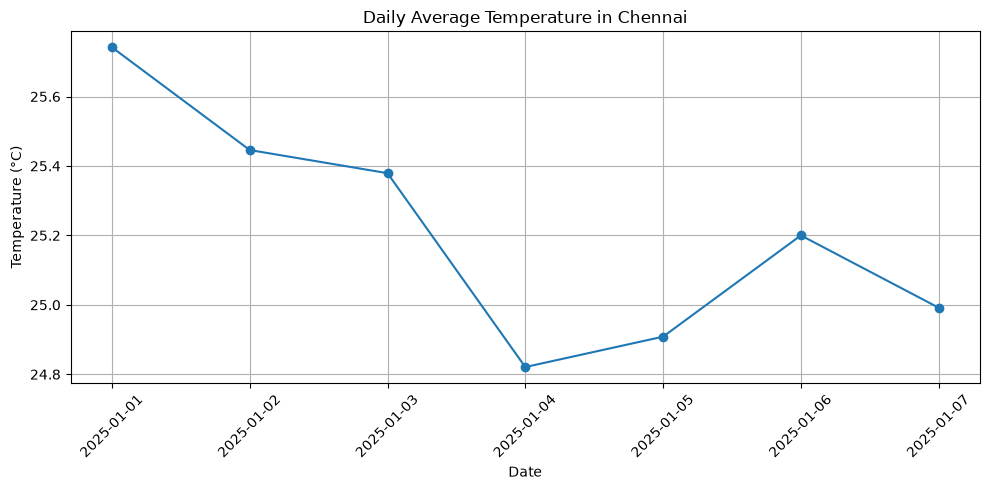

In [5]:

import matplotlib.pyplot as plt

daily_temperature["mean"].plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    title="Daily Average Temperature in Chennai"
)

plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [6]:

from pathlib import Path

output_path = Path("../data/processed/daily_temperature_summary.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

daily_temperature.round(2).to_csv(output_path)

print(f"Saved daily summary to: {output_path}")


Saved daily summary to: ..\data\processed\daily_temperature_summary.csv
